#Importe de librerias y del dataset de Kaggle


In [ ]:
import kagglehub, os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from PIL import ImageOps
import random
import seaborn as sns
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix
import tensorflow as tf
from tensorflow.keras.utils import to_categorical
from tensorflow.keras.models import Sequential, load_model
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint, ReduceLROnPlateau
from tensorflow.keras import layers, models, regularizers
from tensorflow.keras import callbacks as cb
from tensorflow.keras.preprocessing.image import ImageDataGenerator


import kagglehub

# Download latest version
path = kagglehub.dataset_download("balabaskar/wonders-of-the-world-image-classification")

print("Path to dataset files:", path)


# Ver cómo quedó organizado (puede haber una carpeta intermedia)
for root, dirs, files in os.walk(path):
    print(root, "->", len(dirs), "carpetas,", len(files), "archivos")
    break
print(os.listdir(path))

Using Colab cache for faster access to the 'wonders-of-the-world-image-classification' dataset.
Path to dataset files: /kaggle/input/wonders-of-the-world-image-classification
/kaggle/input/wonders-of-the-world-image-classification -> 1 carpetas, 1 archivos
['Wonders of World', 'wonders_of_world_images.csv']


DATA_DIR: /kaggle/input/wonders-of-the-world-image-classification/Wonders of World/Wonders of World
['burj_khalifa', 'chichen_itza', 'christ_the_reedemer', 'eiffel_tower', 'great_wall_of_china', 'machu_pichu', 'pyramids_of_giza', 'roman_colosseum', 'statue_of_liberty', 'stonehenge', 'taj_mahal', 'venezuela_angel_falls']
Total Maravillas: 12 | Total imágenes: 3846
count     12.000000
mean     320.500000
std       85.400128
min      158.000000
25%      247.750000
50%      356.000000
75%      391.250000
max      394.000000
dtype: float64


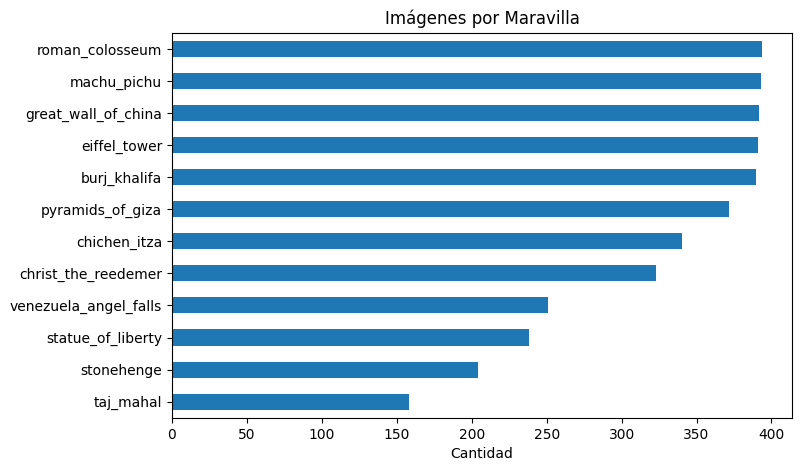

In [ ]:
def solo_carpetas(ruta):
    return sorted(d for d in os.listdir(ruta) if os.path.isdir(os.path.join(ruta, d)))

# Bajar mientras haya una sola subcarpeta (carpetas contenedoras)
DATA_DIR = path
while True:
    sub = solo_carpetas(DATA_DIR)
    if len(sub) == 1:
        DATA_DIR = os.path.join(DATA_DIR, sub[0])
    else:
        break

print("DATA_DIR:", DATA_DIR)

EXT = (".jpg", ".jpeg", ".png", ".webp")
maravillas = solo_carpetas(DATA_DIR)
print(maravillas)   # deben salir las 12 maravillas

conteo = {m: len([f for f in os.listdir(os.path.join(DATA_DIR, m)) if f.lower().endswith(EXT)])
          for m in maravillas}
df_conteo = pd.Series(conteo).sort_values()

print("Total Maravillas:", len(maravillas), "| Total imágenes:", df_conteo.sum())
print(df_conteo.describe())

df_conteo.plot(kind="barh", figsize=(8, 5))
plt.title("Imágenes por Maravilla"); plt.xlabel("Cantidad"); plt.show()

#Proporciones en las imagenes



Imágenes leídas: 3846 | Corruptas: 0
             ancho         alto   proporcion
count  3846.000000  3846.000000  3846.000000
mean    616.568903   457.527041     0.780317
std     603.274610   473.893220     0.329904
min      99.000000   116.000000     0.266667
25%     275.000000   183.000000     0.565139
50%     300.000000   225.000000     0.665455
75%     800.000000   600.000000     0.750000
max    5000.000000  4359.000000     4.030303
modo
RGB    3846
Name: count, dtype: int64


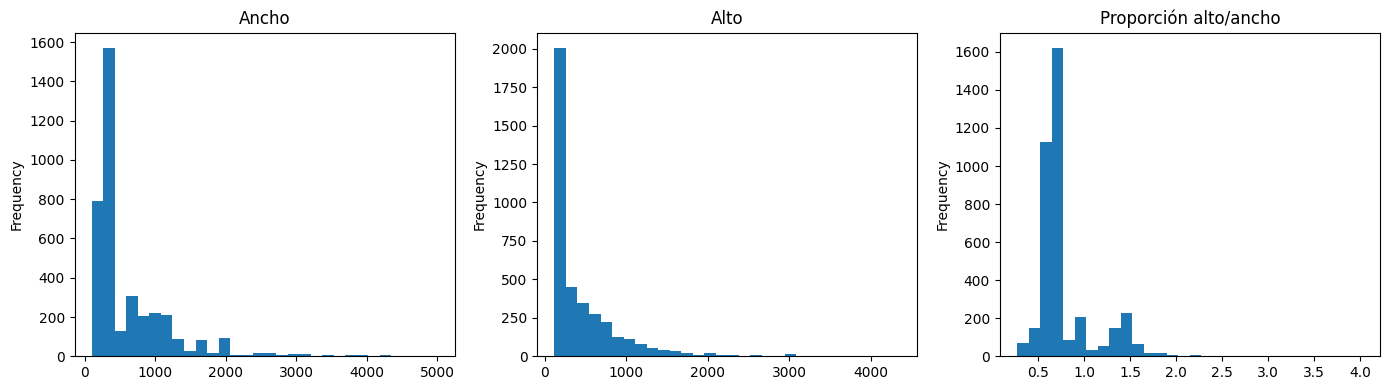

In [ ]:
registros, corruptas = [], []
for r in maravillas:
    for f in os.listdir(os.path.join(DATA_DIR, r)):
        ruta = os.path.join(DATA_DIR, r, f)
        try:
            with Image.open(ruta) as img:
                registros.append({"Maravilla": r, "archivo": f, "ancho": img.width,
                                  "alto": img.height, "modo": img.mode})
        except Exception:
            corruptas.append(ruta)

df_dim = pd.DataFrame(registros)
df_dim["proporcion"] = df_dim["alto"] / df_dim["ancho"]

print("Imágenes leídas:", len(df_dim), "| Corruptas:", len(corruptas))
print(df_dim[["ancho", "alto", "proporcion"]].describe())
print(df_dim["modo"].value_counts())

fig, ax = plt.subplots(1, 3, figsize=(14, 4))
df_dim["ancho"].plot.hist(bins=30, ax=ax[0], title="Ancho")
df_dim["alto"].plot.hist(bins=30, ax=ax[1], title="Alto")
df_dim["proporcion"].plot.hist(bins=30, ax=ax[2], title="Proporción alto/ancho")
plt.tight_layout(); plt.show()

Algunas imágenes:


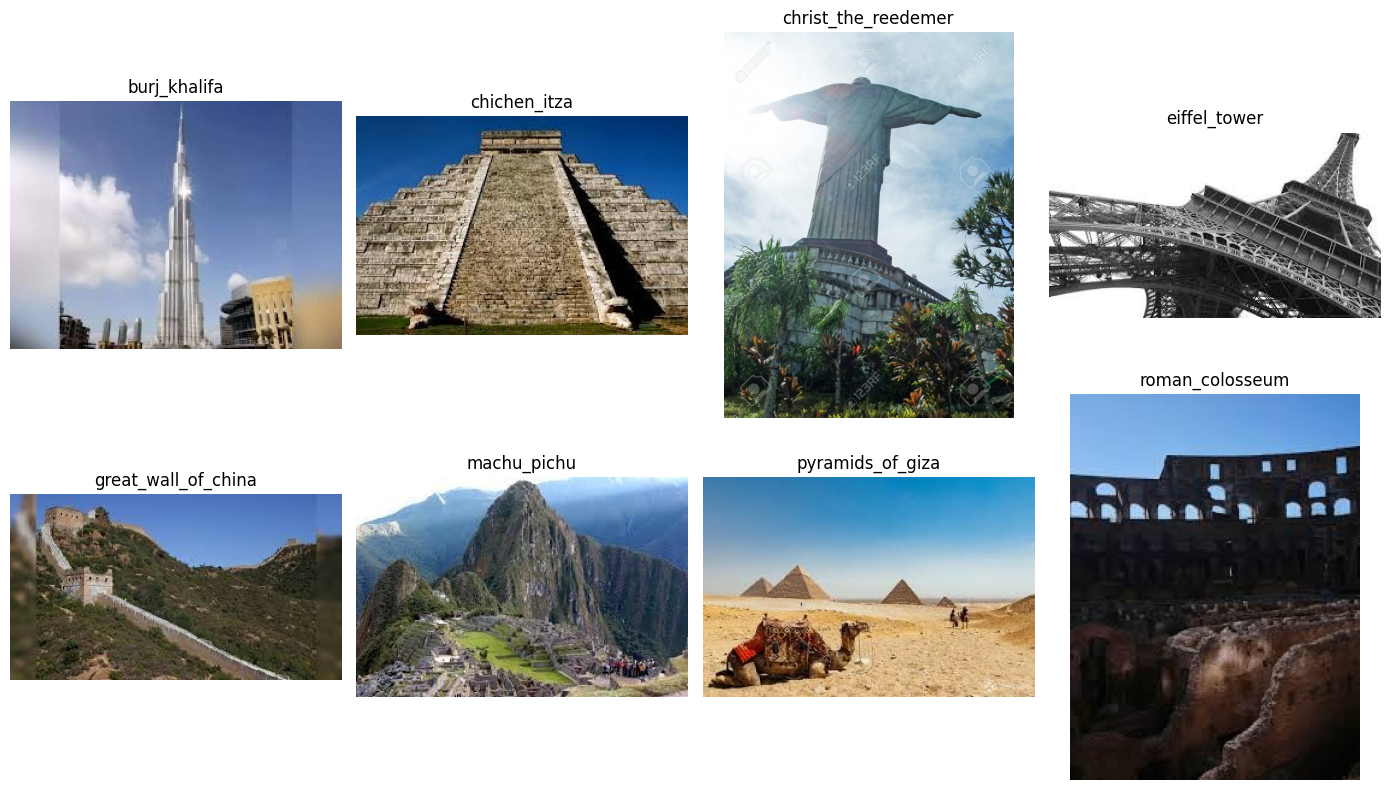

In [ ]:
# Imagencitas de ejemplo
print("Algunas imágenes:")
fig, axes = plt.subplots(2, 4, figsize=(14, 8))
for ax, r in zip(axes.flat, maravillas):
    f = random.choice(os.listdir(os.path.join(DATA_DIR, r)))
    ax.imshow(Image.open(os.path.join(DATA_DIR, r, f)))
    ax.set_title(r); ax.axis("off")
plt.tight_layout(); plt.show()

# Estandarizacion de tamaño


Ese Img Size es para reducir las imagenes a ese tamaño, si hacen en entrenamiento una vez con el 128 pueden cambiar aqui el tamaño a 160/180 y ver si el accuracy mejora, segun lo que busque si mejora solo 2 puntos no compensa el costo en memoria, pero si mejora mas de 2 puntos es mejor entonces aumentar el tamaño

In [ ]:
IMG_SIZE = (128, 128)

rutas, etiquetas = [], []
for r in maravillas:
    for f in os.listdir(os.path.join(DATA_DIR, r)):
        ruta = os.path.join(DATA_DIR, r, f)
        if ruta not in corruptas:
            rutas.append(ruta); etiquetas.append(r)

X = np.zeros((len(rutas), *IMG_SIZE, 3), dtype=np.uint8)   # reserva memoria una sola vez
for i, ruta in enumerate(rutas):
    img = Image.open(ruta)
    img = ImageOps.exif_transpose(img).convert("RGB")       # corrige rotación de fotos de celular
    img = ImageOps.pad(img, IMG_SIZE, color=(0, 0, 0))      # redimensiona SIN deformar (rellena con negro)
    X[i] = np.array(img)

y = np.array(etiquetas)
print(X.shape, X.dtype, X.min(), X.max())

# AQUI VOY A ESCRIBIR LO QUE SIGNIFICA CADA COSO DESPUES EN UNA TABLA
# Total de imágenes cargadas (las 8 razas juntas, sin contar corruptas). 541
# Alto y ancho de cada imagen después de redimensionarla. 128,128
# Canales de color (RGB: rojo, verde, azul). 3
# uint8	Tipo de dato: enteros de 8 bits, es decir, valores de 0 a 255.
# 0 255	Mínimo y máximo de los píxeles: 0 es negro y 255 es el valor más brillante.

(3846, 128, 128, 3) uint8 0 255


#Distribucion para el X y Y train/test

In [ ]:
le = LabelEncoder()
y_num = le.fit_transform(y)
y_cat = to_categorical(y_num)

X_train, X_test, y_train, y_test = train_test_split(
    X, y_cat, test_size=0.12, random_state=42, stratify=y_num
)

# Normalizar a [0, 1] después de dividir
X_train = X_train.astype("float32") / 255.0
X_test = X_test.astype("float32") / 255.0

print("Train:", X_train.shape, "| Test:", X_test.shape)
print("Clases:", le.classes_)
print("Min/Max train:", X_train.min(), X_train.max())

np.savez_compressed("wonders_preprocessed.npz", X_train=X_train, X_test=X_test,
                    y_train=y_train, y_test=y_test, clases=le.classes_)

Train: (3384, 128, 128, 3) | Test: (462, 128, 128, 3)
Clases: ['burj_khalifa' 'chichen_itza' 'christ_the_reedemer' 'eiffel_tower'
 'great_wall_of_china' 'machu_pichu' 'pyramids_of_giza' 'roman_colosseum'
 'statue_of_liberty' 'stonehenge' 'taj_mahal' 'venezuela_angel_falls']
Min/Max train: 0.0 1.0


Aqui les verifico (Otra vez) que las imagenes quedaron todas bien, no hay archivos corruptos ni imagenes en negro (nulas), despues comento bien el resto de codigo pero es para que vean que ya pueden trabajar con esto


Forma de X: (3846, 128, 128, 3)
Proporción alto/ancho: 1.0
Archivos corruptos: 0
Leídas en paso 3: 3846 | Procesadas: 3846 | Etiquetas: 3846
Imágenes totalmente negras: 2
                       original  procesado  train  test  coincide
burj_khalifa                390        390    343    47      True
chichen_itza                340        340    299    41      True
christ_the_reedemer         323        323    284    39      True
eiffel_tower                391        391    344    47      True
great_wall_of_china         392        392    345    47      True
machu_pichu                 393        393    346    47      True
pyramids_of_giza            372        372    327    45      True
roman_colosseum             394        394    347    47      True
statue_of_liberty           238        238    209    29      True
stonehenge                  204        204    180    24      True
taj_mahal                   158        158    139    19      True
venezuela_angel_falls       251      

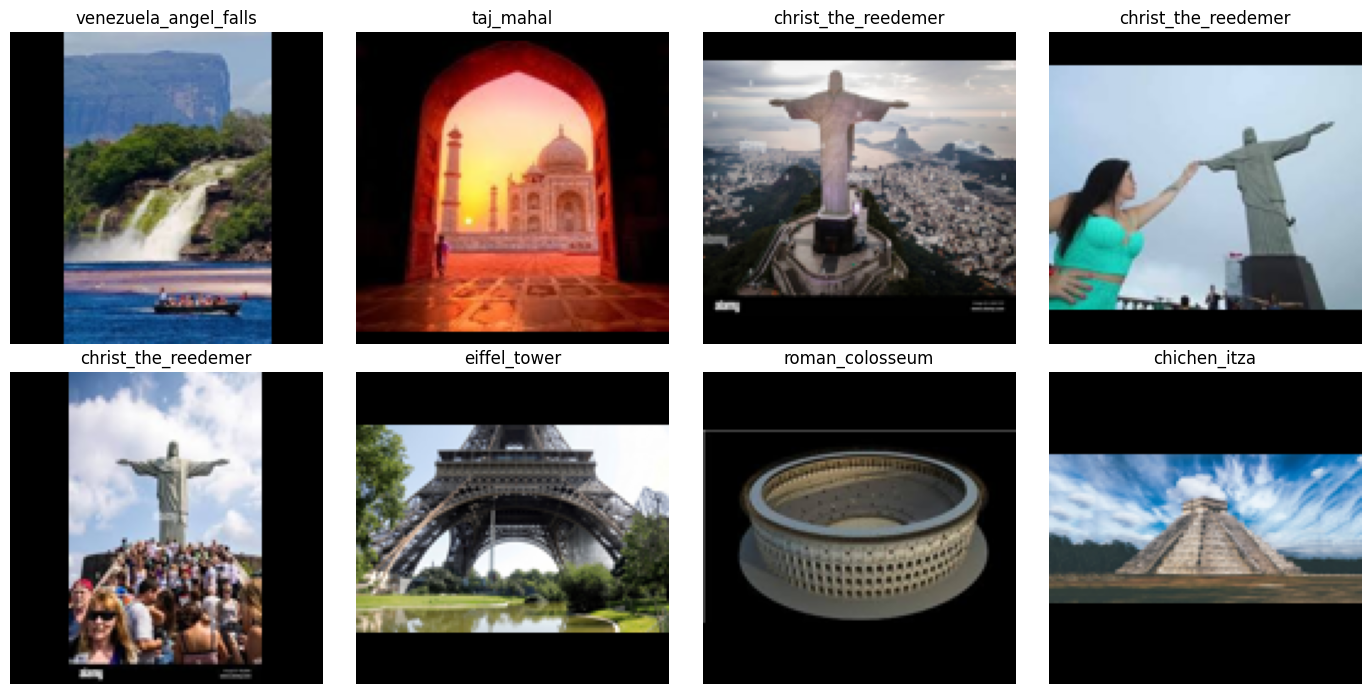

In [ ]:
# 1. Forma: todas las imágenes deben ser 128x128x3
print("Forma de X:", X.shape)
assert X.shape[1:] == (128, 128, 3), "Hay imágenes con tamaño distinto"

# 2. Proporción: alto/ancho debe ser 1.0 (cuadradas)
print("Proporción alto/ancho:", X.shape[1] / X.shape[2])

# 3. Corruptas y consistencia de conteos
print("Archivos corruptos:", len(corruptas))
print("Leídas en paso 3:", len(df_dim), "| Procesadas:", X.shape[0], "| Etiquetas:", len(y))
assert X.shape[0] == len(y) == len(rutas)

# 4. Imágenes completamente negras (señal de una lectura fallida)
vacias = (X.reshape(len(X), -1).max(axis=1) == 0).sum()
print("Imágenes totalmente negras:", vacias)

# 5. Conteo por raza: original vs procesado vs train/test
clases, cuentas = np.unique(y, return_counts=True)
comparacion = pd.DataFrame({
    "original": pd.Series(conteo),
    "procesado": pd.Series(dict(zip(clases, cuentas))),
    "train": pd.Series(le.inverse_transform(y_train.argmax(axis=1))).value_counts(),
    "test": pd.Series(le.inverse_transform(y_test.argmax(axis=1))).value_counts(),
})
comparacion["coincide"] = (comparacion["original"] == comparacion["procesado"]) & \
                          (comparacion["train"] + comparacion["test"] == comparacion["original"])
print(comparacion)

# 6. Rango de valores tras normalizar
print("Rango train:", X_train.min(), "-", X_train.max())


# AJUSTE DE LAS PROPORCIONES DE LAS IMAGENES CON PIXELES NEGROS
# Y vean como se ven las imagenes a las que toco ponerle mas relleno que simon cuando se viste para ver a don Edwin

fig, axes = plt.subplots(2, 4, figsize=(14, 7))
for ax, i in zip(axes.flat, random.sample(range(len(X_train)), 8)):
    ax.imshow(X_train[i])
    ax.set_title(le.classes_[y_train[i].argmax()]); ax.axis("off")
plt.tight_layout(); plt.show()

Arquitectura CNN

In [ ]:
modelo = Sequential([
    #Bloque convolucional 1
    Conv2D(32, (3, 3), activation='relu', padding='same', input_shape=(128, 128, 3)),
    MaxPooling2D((2, 2)),

    #Bloque convolucional 2
    Conv2D(64, (3, 3), activation='relu', padding='same'),
    MaxPooling2D((2, 2)),

    #Bloque convolucional 3
    Conv2D(128, (3, 3), activation='relu', padding='same'),
    MaxPooling2D((2, 2)),

    #Aplanar y clasificar
    Flatten(),
    Dense(128, activation='relu'),
    Dropout(0.5),
    Dense(12, activation='softmax')
])

modelo.summary()

Model: "sequential_11"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_33 (Conv2D)              │ (None, 128, 128, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_33 (MaxPooling2D) │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_34 (Conv2D)              │ (None, 64, 64, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_34 (MaxPooling2D) │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_35 (Conv2D)              │ (None, 32, 32, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_35 (MaxPooling2D) │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_11 (Flatten)            │ (None, 32768)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_22 (Dense)                │ (None, 128)            │     4,194,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_6 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_23 (Dense)                │ (None, 12)             │         1,548 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,289,228 (16.36 MB)

 Trainable params: 4,289,228 (16.36 MB)

 Non-trainable params: 0 (0.00 B)

Compilación del modelo

In [ ]:
modelo.compile(
    optimizer=Adam(learning_rate=0.001),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

Entrenamiento con callbacks **(No volver a ejecutar)**

In [ ]:
callbacks = [
    EarlyStopping(
        monitor='val_loss',
        patience=10,
        restore_best_weights=True,
        verbose=1
    ),
    ModelCheckpoint(
        filepath='mejor_modelo.keras',
        monitor='val_loss',
        save_best_only=True,
        verbose=1
    ),
    ReduceLROnPlateau(
        monitor='val_loss',
        factor=0.5,
        patience=5,
        min_lr=1e-6,
        verbose=1
    )
]

historial = modelo.fit(
    X_train, y_train,
    validation_split=0.15,
    epochs=60,
    batch_size=32,
    callbacks=callbacks,
    verbose=1
)

Epoch 1/60
90/90 ━━━━━━━━━━━━━━━━━━━━ 0s 47ms/step - accuracy: 0.1320 - loss: 2.4873
Epoch 1: val_loss improved from None to 2.02771, saving model to mejor_modelo.keras

Epoch 1: finished saving model to mejor_modelo.keras
90/90 ━━━━━━━━━━━━━━━━━━━━ 10s 72ms/step - accuracy: 0.1808 - loss: 2.3558 - val_accuracy: 0.3386 - val_loss: 2.0277 - learning_rate: 0.0010
Epoch 2/60
90/90 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step - accuracy: 0.2933 - loss: 2.0572
Epoch 2: val_loss improved from 2.02771 to 1.54669, saving model to mejor_modelo.keras

Epoch 2: finished saving model to mejor_modelo.keras
90/90 ━━━━━━━━━━━━━━━━━━━━ 3s 31ms/step - accuracy: 0.3366 - loss: 1.9627 - val_accuracy: 0.5157 - val_loss: 1.5467 - learning_rate: 0.0010
Epoch 3/60
88/90 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step - accuracy: 0.4098 - loss: 1.7602
Epoch 3: val_loss improved from 1.54669 to 1.37925, saving model to mejor_modelo.keras

Epoch 3: finished saving model to mejor_modelo.keras
90/90 ━━━━━━━━━━━━━━━━━━━━ 3s 28ms/step - ac

Cargar el mejor modelo guardado

Test accuracy: 0.7814
Test loss: 0.8327
15/15 ━━━━━━━━━━━━━━━━━━━━ 1s 32ms/step


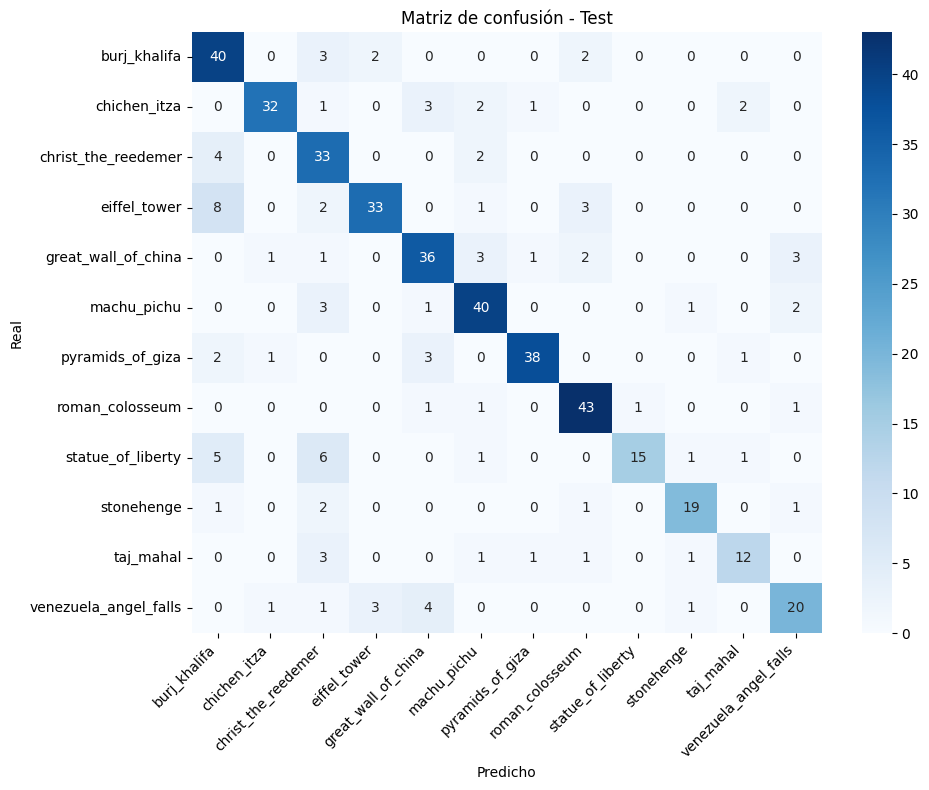

                       precision    recall  f1-score   support

         burj_khalifa     0.6667    0.8511    0.7477        47
         chichen_itza     0.9143    0.7805    0.8421        41
  christ_the_reedemer     0.6000    0.8462    0.7021        39
         eiffel_tower     0.8684    0.7021    0.7765        47
  great_wall_of_china     0.7500    0.7660    0.7579        47
          machu_pichu     0.7843    0.8511    0.8163        47
     pyramids_of_giza     0.9268    0.8444    0.8837        45
      roman_colosseum     0.8269    0.9149    0.8687        47
    statue_of_liberty     0.9375    0.5172    0.6667        29
           stonehenge     0.8261    0.7917    0.8085        24
            taj_mahal     0.7500    0.6316    0.6857        19
venezuela_angel_falls     0.7407    0.6667    0.7018        30

             accuracy                         0.7814       462
            macro avg     0.7993    0.7636    0.7715       462
         weighted avg     0.7991    0.7814    0.7813 

In [ ]:
modelo = load_model("mejor_modelo.keras")

test_loss, test_acc = modelo.evaluate(X_test, y_test, verbose=0)
print(f"Test accuracy: {test_acc:.4f}")
print(f"Test loss: {test_loss:.4f}")

y_prob = modelo.predict(X_test)
y_pred = np.argmax(y_prob, axis=1)
y_true = np.argmax(y_test, axis=1)

cm = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=clases, yticklabels=clases)
plt.xlabel("Predicho")
plt.ylabel("Real")
plt.title("Matriz de confusión - Test")
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

reporte = classification_report(y_true, y_pred, target_names=clases, digits=4)
print(reporte)

np.savez_compressed("predicciones_test.npz",
                    y_true=y_true,
                    y_pred=y_pred,
                    y_prob=y_prob,
                    clases=clases)

Curvas de entrenamiento

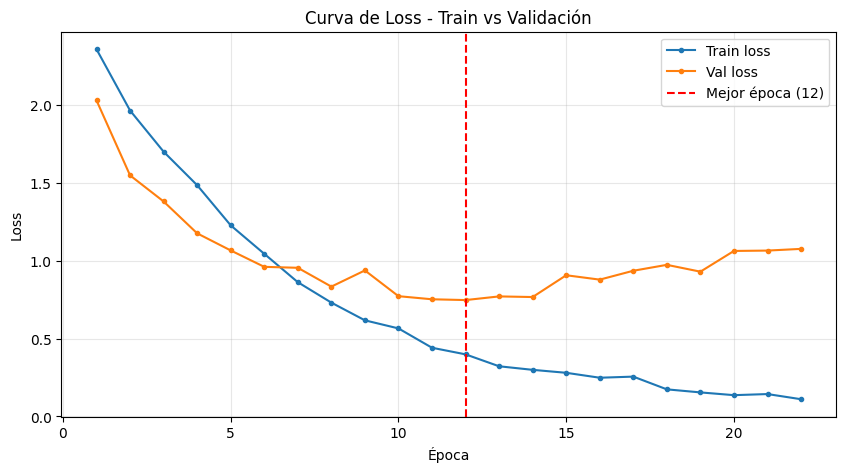

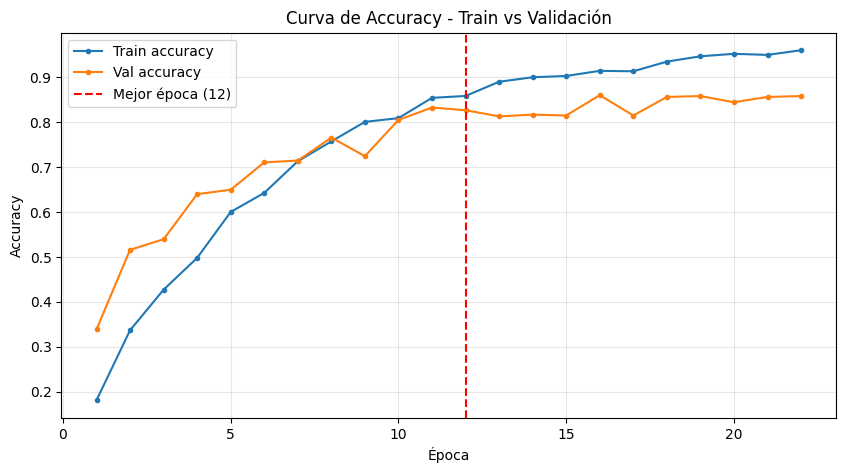

In [ ]:
epocas = range(1, len(historial.history['loss']) + 1)

# Gráfica de Loss
plt.figure(figsize=(10, 5))
plt.plot(epocas, historial.history['loss'], label='Train loss', marker='o', markersize=3)
plt.plot(epocas, historial.history['val_loss'], label='Val loss', marker='o', markersize=3)
plt.axvline(x=12, color='red', linestyle='--', label='Mejor época (12)')
plt.xlabel("Época")
plt.ylabel("Loss")
plt.title("Curva de Loss - Train vs Validación")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

# Gráfica de Accuracy
plt.figure(figsize=(10, 5))
plt.plot(epocas, historial.history['accuracy'], label='Train accuracy', marker='o', markersize=3)
plt.plot(epocas, historial.history['val_accuracy'], label='Val accuracy', marker='o', markersize=3)
plt.axvline(x=12, color='red', linestyle='--', label='Mejor época (12)')
plt.xlabel("Época")
plt.ylabel("Accuracy")
plt.title("Curva de Accuracy - Train vs Validación")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

Guardado del modelo

In [ ]:
modelo.save("modelo_final.keras")
print("Modelo guardado en modelo_final.keras")

print("Tamaño: ", os.path.getsize("modelo_final.keras") / 1024 / 1024, "MB")

modelo_recargado = load_model("modelo_final.keras")
modelo_recargado.summary()

Modelo guardado en modelo_final.keras
Tamaño:  49.13133907318115 MB


Model: "sequential_11"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_33 (Conv2D)              │ (None, 128, 128, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_33 (MaxPooling2D) │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_34 (Conv2D)              │ (None, 64, 64, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_34 (MaxPooling2D) │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_35 (Conv2D)              │ (None, 32, 32, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_35 (MaxPooling2D) │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_11 (Flatten)            │ (None, 32768)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_22 (Dense)                │ (None, 128)            │     4,194,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_6 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_23 (Dense)                │ (None, 12)             │         1,548 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 12,867,686 (49.09 MB)

 Trainable params: 4,289,228 (16.36 MB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 8,578,458 (32.72 MB)

# **Aumento de datos**


In [ ]:
np.random.seed(42)
tf.random.set_seed(42)

# Historial del entrenamiento base (22 épocas; EarlyStopping restauró la época 12).
# NO se vuelve a entrenar.
hist_base = {
    "accuracy":     [0.1808, 0.3366, 0.4270, 0.4979, 0.6001, 0.6426, 0.7131, 0.7573, 0.8008, 0.8091, 0.8543,
                     0.8585, 0.8901, 0.9002, 0.9030, 0.9145, 0.9134, 0.9350, 0.9468, 0.9524, 0.9499, 0.9604],
    "loss":         [2.3558, 1.9627, 1.6986, 1.4835, 1.2260, 1.0435, 0.8615, 0.7304, 0.6168, 0.5650, 0.4409,
                     0.3986, 0.3221, 0.2993, 0.2803, 0.2487, 0.2558, 0.1741, 0.1545, 0.1369, 0.1439, 0.1108],
    "val_accuracy": [0.3386, 0.5157, 0.5394, 0.6398, 0.6496, 0.7106, 0.7146, 0.7657, 0.7244, 0.8051, 0.8327,
                     0.8268, 0.8130, 0.8169, 0.8150, 0.8602, 0.8150, 0.8563, 0.8583, 0.8445, 0.8563, 0.8583],
    "val_loss":     [2.0277, 1.5467, 1.3792, 1.1748, 1.0651, 0.9599, 0.9538, 0.8331, 0.9369, 0.7717, 0.7519,
                     0.7468, 0.7702, 0.7662, 0.9060, 0.8779, 0.9348, 0.9728, 0.9290, 1.0618, 1.0642, 1.0751],
}

# Misma partición que hizo Keras con validation_split=0.15 (toma el ÚLTIMO 15% de X_train)
corte = int(len(X_train) * (1 - 0.15))
X_fit, X_val = X_train[:corte], X_train[corte:]
y_fit, y_val = y_train[:corte], y_train[corte:]

print("X_train completo:", X_train.shape)
print("X_fit (85%, entrenamiento):", X_fit.shape)
print("X_val (15%, validación):", X_val.shape)
print("Rango de píxeles:", X_fit.min(), "-", X_fit.max())

print("\nImágenes por clase en X_fit:")
cont = np.bincount(np.argmax(y_fit, axis=1), minlength=len(le.classes_))
for i, c in enumerate(le.classes_):
    print(f"  {c}: {cont[i]}")

X_train completo: (3384, 128, 128, 3)
X_fit (85%, entrenamiento): (2876, 128, 128, 3)
X_val (15%, validación): (508, 128, 128, 3)
Rango de píxeles: 0.0 - 1.0

Imágenes por clase en X_fit:
  burj_khalifa: 283
  chichen_itza: 252
  christ_the_reedemer: 241
  eiffel_tower: 303
  great_wall_of_china: 287
  machu_pichu: 298
  pyramids_of_giza: 279
  roman_colosseum: 292
  statue_of_liberty: 181
  stonehenge: 154
  taj_mahal: 119
  venezuela_angel_falls: 187


burj_khalifa: 283 -> 300 (+17)
chichen_itza: 252 -> 300 (+48)
christ_the_reedemer: 241 -> 300 (+59)
eiffel_tower: 303 (no necesita aumento)
great_wall_of_china: 287 -> 300 (+13)
machu_pichu: 298 -> 300 (+2)
pyramids_of_giza: 279 -> 300 (+21)
roman_colosseum: 292 -> 300 (+8)
statue_of_liberty: 181 -> 300 (+119)
stonehenge: 154 -> 300 (+146)
taj_mahal: 119 -> 300 (+181)
venezuela_angel_falls: 187 -> 300 (+113)

Entrenamiento original: (2876, 128, 128, 3)
Imágenes generadas: (727, 128, 128, 3)
Entrenamiento aumentado: (3603, 128, 128, 3)

Cantidad final por clase:
  burj_khalifa: 300
  chichen_itza: 300
  christ_the_reedemer: 300
  eiffel_tower: 303
  great_wall_of_china: 300
  machu_pichu: 300
  pyramids_of_giza: 300
  roman_colosseum: 300
  statue_of_liberty: 300
  stonehenge: 300
  taj_mahal: 300
  venezuela_angel_falls: 300


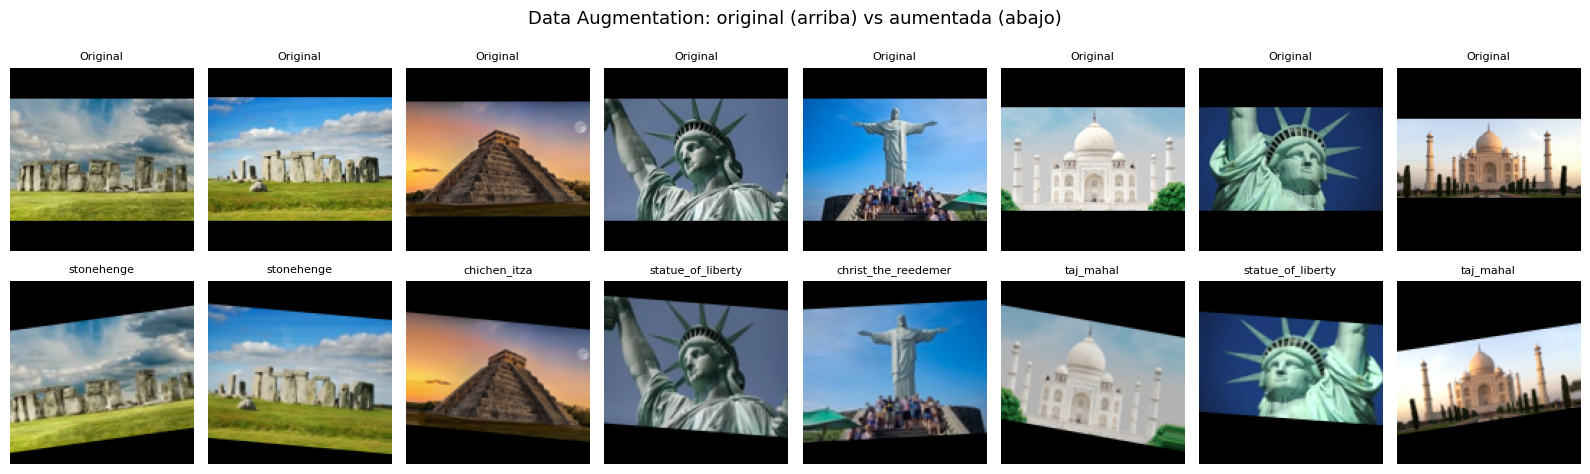

In [ ]:
# Rotación, volteo, zoom y desplazamientos con Keras.
# El brillo se aplica aparte para evitar imágenes negras.
datagen = ImageDataGenerator(
    rotation_range=10,
    horizontal_flip=True,
    zoom_range=0.10,
    width_shift_range=0.05,
    height_shift_range=0.05,
    fill_mode='nearest'
)

OBJETIVO = 300   # puedes subirlo a 400

def aumentar(img):
    """img: (128,128,3) en [0,1]. Devuelve una versión transformada."""
    nueva = datagen.random_transform(img.astype("float32"))
    factor = np.random.uniform(0.85, 1.15)            # cambio de brillo
    return np.clip(nueva * factor, 0, 1).astype("float32")

clases_fit = np.argmax(y_fit, axis=1)
X_extra, y_extra, origen = [], [], []

for clase in range(len(le.classes_)):
    indices = np.where(clases_fit == clase)[0]
    necesarias = OBJETIVO - len(indices)
    if necesarias <= 0:
        print(f"{le.classes_[clase]}: {len(indices)} (no necesita aumento)")
        continue
    print(f"{le.classes_[clase]}: {len(indices)} -> {OBJETIVO} (+{necesarias})")
    for _ in range(necesarias):
        idx = np.random.choice(indices)
        X_extra.append(aumentar(X_fit[idx]))
        y_extra.append(y_fit[idx])
        origen.append(idx)

if len(X_extra) > 0:
    X_extra = np.array(X_extra, dtype=np.float32)
    y_extra = np.array(y_extra, dtype=np.float32)
    X_fit_aug = np.concatenate([X_fit, X_extra], axis=0)
    y_fit_aug = np.concatenate([y_fit, y_extra], axis=0)
else:
    X_extra = np.empty((0, *X_fit.shape[1:]), dtype=np.float32)
    y_extra = np.empty((0, y_fit.shape[1]), dtype=np.float32)
    X_fit_aug, y_fit_aug = X_fit.copy(), y_fit.copy()

print("\nEntrenamiento original:", X_fit.shape)
print("Imágenes generadas:", X_extra.shape)
print("Entrenamiento aumentado:", X_fit_aug.shape)

print("\nCantidad final por clase:")
cont_f = np.bincount(np.argmax(y_fit_aug, axis=1), minlength=len(le.classes_))
for i, c in enumerate(le.classes_):
    print(f"  {c}: {cont_f[i]}")

# Ejemplos: fila de arriba = original, fila de abajo = aumentada
if len(X_extra) > 0:
    n = min(8, len(X_extra))
    muestra = np.random.choice(len(X_extra), size=n, replace=False)
    plt.figure(figsize=(16, 5))
    for i, k in enumerate(muestra):
        plt.subplot(2, n, i + 1)
        plt.imshow(np.clip(X_fit[origen[k]], 0, 1))
        plt.title("Original", fontsize=8)
        plt.axis("off")
        plt.subplot(2, n, n + i + 1)
        plt.imshow(np.clip(X_extra[k], 0, 1))
        plt.title(le.classes_[np.argmax(y_extra[k])], fontsize=8)
        plt.axis("off")
    plt.suptitle("Data Augmentation: original (arriba) vs aumentada (abajo)", fontsize=13)
    plt.tight_layout()
    plt.show()

In [ ]:
def epoca_overfitting(h):
    """Época con menor val_loss: a partir de ahí empieza el overfitting."""
    return int(np.argmin(h["val_loss"])) + 1

def graficar(nombre, h):
    ep = range(1, len(h["loss"]) + 1)
    e = epoca_overfitting(h)
    fig, ax = plt.subplots(1, 2, figsize=(13, 4))
    for a, k, t in zip(ax, ["loss", "accuracy"], ["Loss", "Accuracy"]):
        a.plot(ep, h[k], label="Train")
        a.plot(ep, h["val_" + k], label="Validación")
        a.axvline(e, color="red", ls="--", label=f"Inicio overfitting (época {e})")
        a.set_title(f"{t} - {nombre}")
        a.set_xlabel("Época")
        a.legend()
    plt.tight_layout()
    plt.show()

def resumen(nombre, h, early):
    b = int(np.argmin(h["val_loss"]))
    # Con EarlyStopping el modelo final es el de la mejor época; sin él, el de la última.
    i = b if early else len(h["loss"]) - 1
    acc_tr, acc_val = h["accuracy"][i], h["val_accuracy"][i]
    brecha = acc_tr - acc_val
    return {
        "Configuración": nombre,
        "Épocas": len(h["loss"]),
        "Época overfit": b + 1,
        "Acc Train": round(acc_tr, 3),
        "Acc Val": round(acc_val, 3),
        "Brecha (train-val)": round(brecha, 3),
        "Overfitting": "Sí" if brecha > 0.10 else "No",
    }

Modelo con las iamgenes generadas **(NO EJECUTAR)**

In [ ]:
import time


EPOCAS = 60
PACIENCIA = 10


def construir_modelo(dropout=0.0, l2=0.0, batchnorm=False, lr=0.001):
    """Misma arquitectura del equipo: 3 bloques Conv (32/64/128) + Dense(128) + Dropout + Dense(12)."""
    reg = regularizers.l2(l2) if l2 > 0 else None
    m = models.Sequential([layers.Input(shape=(128, 128, 3))])
    for f in [32, 64, 128]:
        m.add(layers.Conv2D(f, (3, 3), padding="same", kernel_regularizer=reg))
        if batchnorm:
            m.add(layers.BatchNormalization())
        m.add(layers.Activation("relu"))
        m.add(layers.MaxPooling2D((2, 2)))
    m.add(layers.Flatten())
    m.add(layers.Dense(128, activation="relu", kernel_regularizer=reg))
    if dropout > 0:
        m.add(layers.Dropout(dropout))
    m.add(layers.Dense(12, activation="softmax"))
    m.compile(optimizer=Adam(learning_rate=lr),
              loss="categorical_crossentropy", metrics=["accuracy"])
    return m

def entrenar(nombre, Xd, yd, dropout=0.0, l2=0.0, batchnorm=False, early=True, lr=0.001):
    print(f"\n>>> Entrenando: {nombre}")
    cbs = []
    if early:
        cbs = [
            cb.EarlyStopping(monitor="val_loss", patience=PACIENCIA, restore_best_weights=True),
            cb.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=5, min_lr=1e-7),
        ]
    m = construir_modelo(dropout, l2, batchnorm, lr)
    h = m.fit(Xd, yd, validation_data=(X_val, y_val),
              epochs=EPOCAS, batch_size=32, callbacks=cbs, verbose=2)
    return h.history

#   nombre,                                    (datos),                  dropout, l2,   bn,    early, lr
exps = [
    ("Sin regularización (sin Dropout ni ES)",  (X_fit, y_fit),          0.0, 0.0,  False, False, 1e-3),
    ("Solo EarlyStopping (sin Dropout)",        (X_fit, y_fit),          0.0, 0.0,  False, True,  1e-3),
    ("Dropout 0.3 + ES",                        (X_fit, y_fit),          0.3, 0.0,  False, True,  1e-3),
    ("Dropout 0.7 + ES",                        (X_fit, y_fit),          0.7, 0.0,  False, True,  1e-3),
    ("Data Augmentation + ES",                  (X_fit_aug, y_fit_aug),  0.0, 0.0,  False, True,  1e-3),
    ("L2 (0.001) + ES",                         (X_fit, y_fit),          0.0, 1e-3, False, True,  1e-3),
    ("BatchNorm + ES",                          (X_fit, y_fit),          0.0, 0.0,  True,  True,  1e-4),
    ("Aug + Dropout 0.5 + ES",                  (X_fit_aug, y_fit_aug),  0.5, 0.0,  False, True,  1e-3),
    ("COMBINADO (Aug+Dropout 0.5+L2+BN+ES)",    (X_fit_aug, y_fit_aug),  0.5, 1e-3, True,  True,  1e-4),
]

NOMBRE_BASE = "Base equipo (Dropout 0.5 + ES)"

if "historiales" not in globals():
    historiales = {NOMBRE_BASE: (hist_base, True)}

# Borra los dos entrenamientos que fallaron para que se repitan
for k in ["BatchNorm + ES", "COMBINADO (Aug+Dropout 0.5+L2+BN+ES)"]:
    historiales.pop(k, None)

inicio_total = time.time()
for nombre, (Xd, yd), d, l2, bn, es, lr in exps:
    if nombre in historiales:
        print(f"[omitido, ya entrenado] {nombre}")
        continue
    t0 = time.time()
    historiales[nombre] = (entrenar(nombre, Xd, yd, d, l2, bn, es, lr), es)
    print(f"Terminado en {(time.time() - t0) / 60:.1f} min")

# Ordenar según la lista de experimentos
orden = [NOMBRE_BASE] + [e[0] for e in exps]
historiales = {k: historiales[k] for k in orden if k in historiales}

print(f"\nTiempo total de esta ejecución: {(time.time() - inicio_total) / 60:.1f} min")

[omitido, ya entrenado] Sin regularización (sin Dropout ni ES)
[omitido, ya entrenado] Solo EarlyStopping (sin Dropout)
[omitido, ya entrenado] Dropout 0.3 + ES
[omitido, ya entrenado] Dropout 0.7 + ES
[omitido, ya entrenado] Data Augmentation + ES
[omitido, ya entrenado] L2 (0.001) + ES

>>> Entrenando: BatchNorm + ES
Epoch 1/60
90/90 - 12s - 128ms/step - accuracy: 0.3595 - loss: 2.0126 - val_accuracy: 0.1850 - val_loss: 2.5847 - learning_rate: 1.0000e-04
Epoch 2/60
90/90 - 3s - 28ms/step - accuracy: 0.6019 - loss: 1.2442 - val_accuracy: 0.2362 - val_loss: 2.8641 - learning_rate: 1.0000e-04
Epoch 3/60
90/90 - 3s - 29ms/step - accuracy: 0.7476 - loss: 0.8674 - val_accuracy: 0.2382 - val_loss: 2.9871 - learning_rate: 1.0000e-04
Epoch 4/60
90/90 - 3s - 28ms/step - accuracy: 0.8418 - loss: 0.6022 - val_accuracy: 0.3504 - val_loss: 2.6411 - learning_rate: 1.0000e-04
Epoch 5/60
90/90 - 2s - 27ms/step - accuracy: 0.9009 - loss: 0.4268 - val_accuracy: 0.5453 - val_loss: 1.8051 - learning_rate

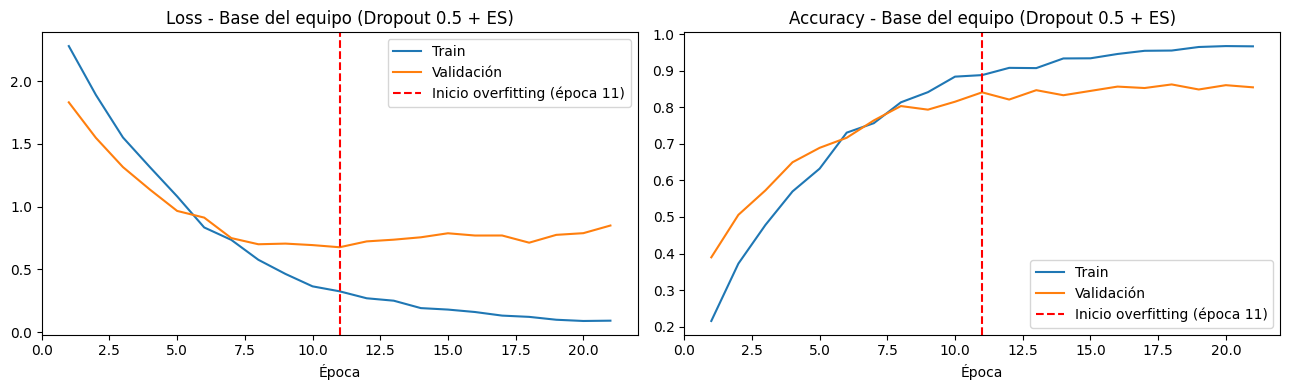

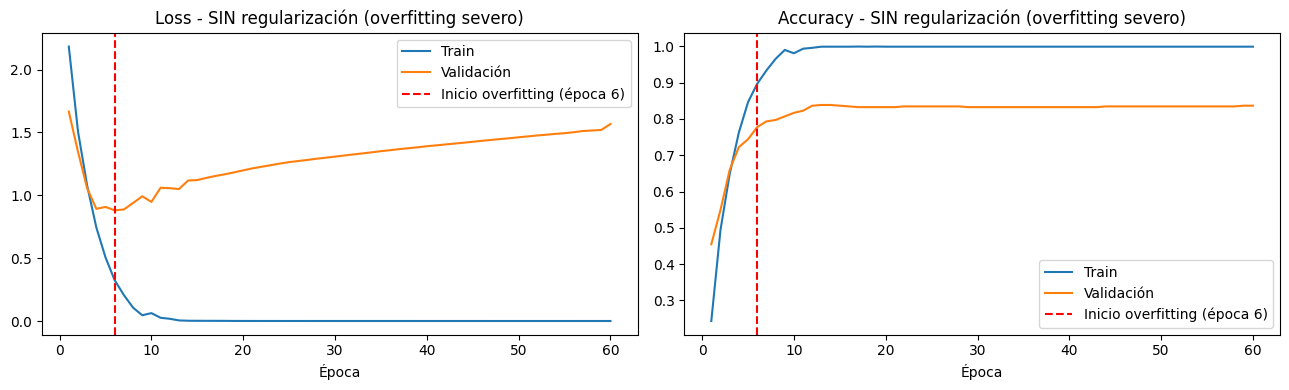

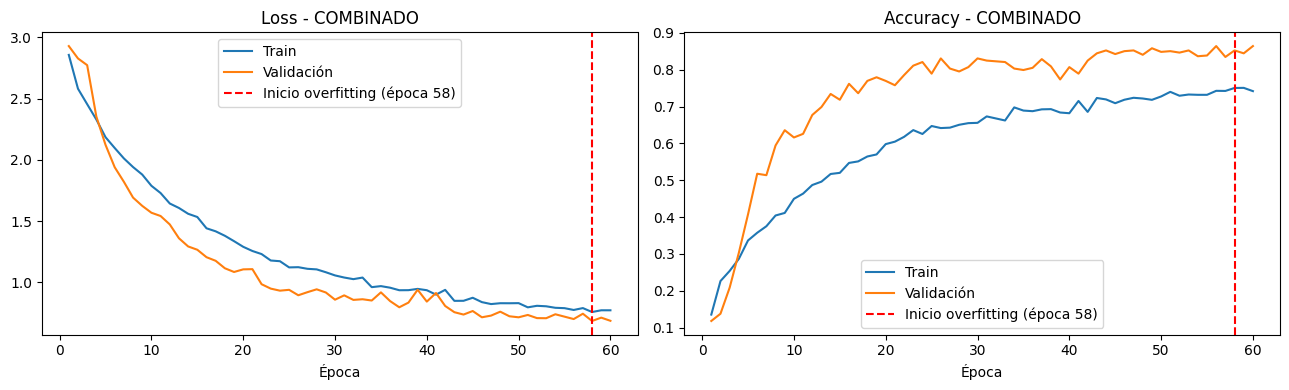

,Configuración,Épocas,Época overfit,Acc Train,Acc Val,Brecha (train-val),Overfitting
0,Base equipo (Dropout 0.5 + ES),21,11,0.888,0.841,0.047,No
1,Sin regularización (sin Dropout ni ES),60,6,0.999,0.837,0.163,Sí
2,Solo EarlyStopping (sin Dropout),16,6,0.882,0.778,0.105,Sí
3,Dropout 0.3 + ES,21,11,0.938,0.827,0.111,Sí
4,Dropout 0.7 + ES,29,19,0.797,0.844,-0.048,No
5,Data Augmentation + ES,16,6,0.923,0.817,0.106,Sí
6,L2 (0.001) + ES,35,25,0.926,0.795,0.131,Sí
7,BatchNorm + ES,35,25,1.000,0.856,0.143,Sí
8,Aug + Dropout 0.5 + ES,20,10,0.860,0.839,0.021,No
9,COMBINADO (Aug+Dropout 0.5+L2+BN+ES),60,58,0.750,0.852,-0.102,No


In [ ]:
graficar("Base del equipo (Dropout 0.5 + ES)", historiales[NOMBRE_BASE][0])
graficar("SIN regularización (overfitting severo)",
         historiales["Sin regularización (sin Dropout ni ES)"][0])
graficar("COMBINADO",
         historiales["COMBINADO (Aug+Dropout 0.5+L2+BN+ES)"][0])

tabla = pd.DataFrame([resumen(n, h, es) for n, (h, es) in historiales.items()])
display(tabla)